# BOSZ subset validation with the refactored NMF API

A diagnostic experiment using a small **parameter-stratified MARCS subset**, with independent validation groups. It tests the recommendations in [the NMF diagnostic report](../NMF_diagnostic_report_codex.md) using `SpectralNMF`, `NMFCache`, `ContinuumResponseBasis`, and `ContinuumNormalizer`, without using the old 3000-point processed flux cache.

Run `uv sync` from the repository root and use that project's Python environment. Run this notebook with `sandbox/` as its working directory; output files go to `../reports/`. The configuration below caps training at three spectra and validation at one spectrum per occupied temperature/gravity/metallicity stratum (at most 108 + 36 spectra). Reading compressed raw files can take several minutes. The experiment uses only 3800–4200 Å at R≈115,000; it is not a full-grid benchmark or a replication of the complete paper training.

The current Gaussian convolution prescription retains the provisional `R_in=300000` assumption. Native `rorig` resolution varies, so resolution calibration remains a separate task. This notebook isolates sampling, thresholding, and factorization choices while holding that prescription fixed.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sqlite3
import time
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import sklearn
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from matplotlib import pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

from src.load_spectra import BOSZSpectra
from src.model import SpectralNMF, NMFCache, ContinuumNormalizer, ContinuumResponseBasis

DATA_ROOT = Path('/home/mward19/nobackup/autodelete/bosz-spectra/data')
INDEX_PATH = DATA_ROOT.parent / 'processed-harps/spectra_index.sqlite'
OUTPUT_ROOT = Path('../reports/bosz_subset_validation')
SEED = 20261113
TRAIN_PER_STRATUM = 3
VALIDATION_PER_STRATUM = 1
MAX_STRATA = None  # Optional small smoke run; None covers every eligible stratum.
K = 16
MAX_ITER = 500
TOL = 1e-4
R_IN = 300_000  # Provisional Gaussian input width, not a measured width for every rorig file.
R_OUT = 115_000
WAVE_MIN, WAVE_MAX = 3800.0, 4200.0
FLUX_FLOOR = 1e-8
N_THREADS = 1

TEFF_EDGES = [2800, 4000, 5500, 7000, 8001]
LOGG_EDGES = [-1, 2, 4, 6]
METAL_EDGES = [-3, -1, 0, 1]

assert DATA_ROOT.is_dir(), f'Configure DATA_ROOT first: {DATA_ROOT}'
assert TRAIN_PER_STRATUM >= 1 and VALIDATION_PER_STRATUM >= 1
assert WAVE_MIN < WAVE_MAX and 0 < R_OUT < R_IN

def wavelength_grid(samples_per_fwhm):
    n = 1 + int(np.ceil(samples_per_fwhm * R_OUT * np.log(WAVE_MAX / WAVE_MIN)))
    return np.geomspace(WAVE_MIN, WAVE_MAX, n)

reference_wave = wavelength_grid(4)
print(f'Reference grid: {len(reference_wave):,} pixels, 4 samples/FWHM')

Reference grid: 46,040 pixels, 4 samples/FWHM


## Select physical groups before reading flux

Strata balance coarse bins in temperature, gravity, and metallicity. Within each stratum we sample **distinct `(Teff, logg, [M/H])` groups**, then choose one available atmosphere/abundance/microturbulence variant per group. This prevents near-duplicate chemical variants of the same physical group from crossing the train/validation boundary. It is stricter than randomly splitting individual filenames.

Alpha abundance, carbon abundance, and microturbulence are sampled reproducibly among available variants and audited below; they are not additional fully crossed strata. Equal stratum weighting is a diagnostic design, not a claim about the distribution of real stars. Sparse and unoccupied bins are reported.

If available, the old SQLite database is opened **read-only for its filename index**. No cached processed flux is read. Otherwise filenames are scanned directly.

In [2]:
fields = ['atmos', 'teff', 'logg', 'metal', 'alpha', 'carbon', 'micro', 'insbroad', 'prod']
if INDEX_PATH.is_file():
    uri = INDEX_PATH.resolve().as_uri() + '?mode=ro'
    with sqlite3.connect(uri, uri=True) as conn:
        metadata = pd.read_sql_query(
            "SELECT source_file, " + ', '.join(fields) +
            " FROM spectra WHERE atmos IN ('mp', 'ms') "
            "AND insbroad='rorig' AND prod='noresam'", conn)
    # Standard BOSZ 2024 download layout used by this repository.
    metadata['filepath'] = [str(DATA_ROOT / 'rorig' / metal / name)
                            for metal, name in zip(metadata.metal, metadata.source_file)]
else:
    rows = []
    for path in DATA_ROOT.rglob('bosz2024_*.txt.gz'):
        parts = path.name.removesuffix('.txt.gz').split('_')
        if len(parts) != 10:
            continue
        row = dict(zip(fields, parts[1:]))
        if row['atmos'] in ('mp', 'ms') and row['insbroad'] == 'rorig' and row['prod'] == 'noresam':
            rows.append({**row, 'source_file': path.name, 'filepath': str(path)})
    metadata = pd.DataFrame(rows)
if metadata.empty:
    raise ValueError('No MARCS rorig/noresam spectra were found.')

for column, prefix in [('teff', 't'), ('logg', 'g'), ('metal', 'm'),
                       ('alpha', 'a'), ('carbon', 'c'), ('micro', 'v')]:
    metadata[column] = metadata[column].str.removeprefix(prefix).astype(float)
metadata = metadata.loc[metadata.teff.between(2800, 8000)].copy()
metadata['t_bin'] = pd.cut(metadata.teff, TEFF_EDGES, right=False, labels=False)
metadata['g_bin'] = pd.cut(metadata.logg, LOGG_EDGES, right=False, labels=False)
metadata['m_bin'] = pd.cut(metadata.metal, METAL_EDGES, right=False, labels=False)
metadata = metadata.dropna(subset=['t_bin', 'g_bin', 'm_bin']).sort_values('filepath')
stratum_columns = ['t_bin', 'g_bin', 'm_bin']
group_columns = ['teff', 'logg', 'metal']

rng = np.random.default_rng(SEED)
selected, coverage = [], []
used_strata = 0
for key, frame in metadata.groupby(stratum_columns, sort=True):
    groups = list(frame.groupby(group_columns, sort=True))
    n_validation = min(VALIDATION_PER_STRATUM, max(0, len(groups) - 1))
    n_train = min(TRAIN_PER_STRATUM, len(groups) - n_validation)
    use = n_validation > 0 and n_train > 0 and (MAX_STRATA is None or used_strata < MAX_STRATA)
    coverage.append(dict(zip(stratum_columns, key)) | {
        'available_groups': len(groups), 'selected_train': n_train if use else 0,
        'selected_validation': n_validation if use else 0})
    if not use:
        continue
    used_strata += 1
    order = rng.permutation(len(groups))[:n_train + n_validation]
    for j, index in enumerate(order):
        _, variants = groups[index]
        row = variants.iloc[int(rng.integers(len(variants)))].to_dict()
        row['split'] = 'train' if j < n_train else 'validation'
        selected.append(row)

selection = pd.DataFrame(selected).reset_index(drop=True)
coverage = pd.DataFrame(coverage)
if selection.empty:
    raise ValueError('No strata have enough distinct physical groups for validation.')
train_mask = selection.split.eq('train').to_numpy()
validation_mask = ~train_mask
train_groups = set(map(tuple, selection.loc[train_mask, group_columns].to_numpy()))
validation_groups = set(map(tuple, selection.loc[validation_mask, group_columns].to_numpy()))
assert train_groups.isdisjoint(validation_groups)
assert selection.filepath.is_unique
assert train_mask.sum() >= K, 'Reduce K or select more training groups.'
missing = [p for p in selection.filepath if not Path(p).is_file()]
if missing:
    raise FileNotFoundError(f'Index paths do not match DATA_ROOT; example: {missing[0]}')

print(f'{train_mask.sum()} training and {validation_mask.sum()} validation spectra, {used_strata} strata')
display(coverage)
display(selection.groupby('split')[['teff', 'logg', 'metal', 'alpha', 'carbon', 'micro']].agg(['min', 'max', 'nunique']))
print('Sampled alpha, carbon and microturbulence values:')
for column in ['alpha', 'carbon', 'micro']:
    print(column, sorted(selection[column].unique()))

108 training and 36 validation spectra, 36 strata


,t_bin,g_bin,m_bin,available_groups,selected_train,selected_validation
0,0,0,0,287,3,1
1,0,0,1,232,3,1
2,0,0,2,240,3,1
3,0,1,0,288,3,1
4,0,1,1,192,3,1
5,0,1,2,192,3,1
6,0,2,0,287,3,1
7,0,2,1,192,3,1
8,0,2,2,192,3,1
9,1,0,0,130,3,1


teff                 logg              metal                \
               min     max nunique  min  max nunique   min   max nunique   
split                                                                      
train       2800.0  8000.0      26 -0.5  5.5      13  -2.5  0.75      14   
validation  2900.0  7750.0      20  0.0  5.5      12  -2.5  0.75      13   

           alpha              carbon              micro               
             min  max nunique    min  max nunique   min  max nunique  
split                                                                 
train      -0.25  0.5       4  -0.75  0.5       6   0.0  4.0       4  
validation -0.25  0.5       4  -0.75  0.5       6   0.0  4.0       4

Sampled alpha, carbon and microturbulence values:
alpha [np.float64(-0.25), np.float64(0.0), np.float64(0.25), np.float64(0.5)]
carbon [np.float64(-0.75), np.float64(-0.5), np.float64(-0.25), np.float64(0.0), np.float64(0.25), np.float64(0.5)]
micro [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(4.0)]


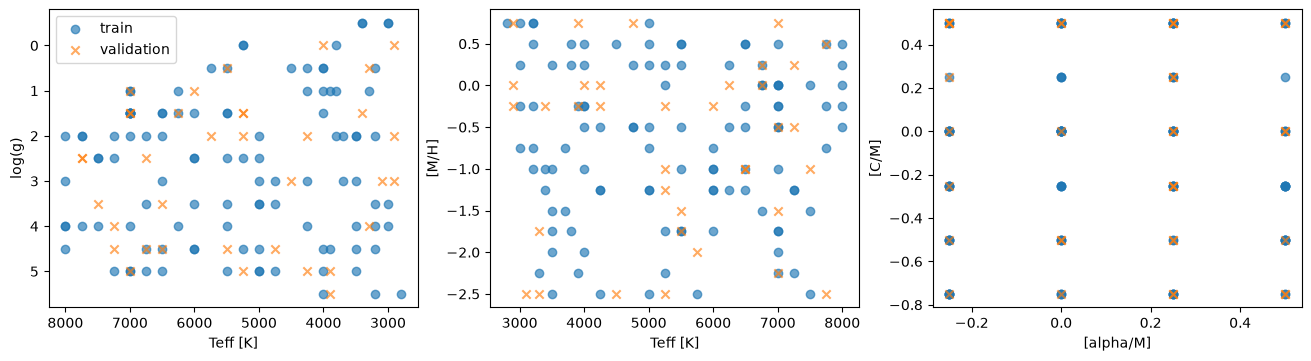

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
for split, marker in [('train', 'o'), ('validation', 'x')]:
    rows = selection[selection.split == split]
    axes[0].scatter(rows.teff, rows.logg, marker=marker, alpha=.65, label=split)
    axes[1].scatter(rows.teff, rows.metal, marker=marker, alpha=.65)
    axes[2].scatter(rows.alpha, rows.carbon, marker=marker, alpha=.65)
axes[0].set(xlabel='Teff [K]', ylabel='log(g)'); axes[0].invert_xaxis(); axes[0].invert_yaxis(); axes[0].legend()
axes[1].set(xlabel='Teff [K]', ylabel='[M/H]')
axes[2].set(xlabel='[alpha/M]', ylabel='[C/M]')
plt.show()

## Prepare a fresh, finely sampled reference subset

Read each selected raw spectrum, divide by its theoretical continuum, sort and merge duplicate wavelength samples, convolve **flux** on a padded interval, and sample at four points per instrumental FWHM. All experiments are derived from this same unthresholded reference.

Each run creates a new output directory, including the selection manifest, source sizes/mtimes, explicit wavelength array, processing parameters and software versions. Outputs never overwrite the production processed spectra or NMF caches. The reference is still a sampled numerical approximation; it is not a calibrated instrumental simulator.

In [4]:
job_id = os.environ.get('SLURM_JOB_ID')
run_label = f'slurm_{job_id}' if job_id else datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
run_dir = OUTPUT_ROOT / run_label
# Allow independent repeated notebook executions within one Slurm job.
if run_dir.exists():
    run_dir = OUTPUT_ROOT / f'{run_label}_{time.time_ns()}'
run_dir.mkdir(parents=True)
selection.to_csv(run_dir / 'selection.csv', index=False)
coverage.to_csv(run_dir / 'stratum_coverage.csv', index=False)
source_manifest = [{'path': p, 'size': Path(p).stat().st_size, 'mtime_ns': Path(p).stat().st_mtime_ns}
                   for p in selection.filepath]
config = dict(seed=SEED, K=K, max_iter=MAX_ITER, tol=TOL, R_in=R_IN, R_out=R_OUT,
              wave_min=WAVE_MIN, wave_max=WAVE_MAX, reference_samples_per_fwhm=4,
              flux_floor=FLUX_FLOOR, train_per_stratum=TRAIN_PER_STRATUM,
              validation_per_stratum=VALIDATION_PER_STRATUM, max_strata=MAX_STRATA,
              teff_edges=TEFF_EDGES, logg_edges=LOGG_EDGES, metal_edges=METAL_EDGES,
              threads=N_THREADS, slurm_job_id=job_id,
              versions=dict(python=platform.python_version(), numpy=np.__version__,
                            scipy=scipy.__version__, sklearn=sklearn.__version__, pandas=pd.__version__),
              sources=source_manifest,
              manifest_sha256=hashlib.sha256(selection.to_csv(index=False).encode()).hexdigest())
(run_dir / 'run_config.json').write_text(json.dumps(config, indent=2))

raw_reference_example = None
clipped_counts = []
reference_flux = np.empty((len(selection), len(reference_wave)), dtype=np.float32)
preprocessing_start = time.perf_counter()
for i, row in tqdm(selection.iterrows(), total=len(selection), desc='Read and convolve selected BOSZ spectra'):
    raw = np.loadtxt(row.filepath, dtype=np.float64)
    keep = (raw[:, 0] >= WAVE_MIN - 20) & (raw[:, 0] <= WAVE_MAX + 20)
    raw = raw[keep]
    if len(raw) < 2 or not np.isfinite(raw).all() or np.any(raw[:, 2] <= 0):
        raise ValueError(f'Invalid flux/continuum or wavelength values: {row.filepath}')
    wave, inverse, counts = np.unique(raw[:, 0], return_inverse=True, return_counts=True)
    flux = np.bincount(inverse, weights=raw[:, 1] / raw[:, 2]) / counts
    if wave[0] > WAVE_MIN or wave[-1] < WAVE_MAX:
        raise ValueError(f'Insufficient wavelength coverage: {row.filepath}')
    convolved = BOSZSpectra.convolve_to_R(np.column_stack([wave, flux]), R_IN, R_OUT)
    sampled = np.interp(reference_wave, wave, convolved)
    clipped_counts.append(int(np.count_nonzero((sampled <= 0) | (sampled > 1))))
    reference_flux[i] = np.clip(sampled, FLUX_FLOOR, 1)
    if raw_reference_example is None or abs(row.teff - 6000) < raw_reference_example['distance']:
        raw_reference_example = dict(wave=wave.copy(), flux=convolved.copy(), distance=abs(row.teff-6000), teff=row.teff)
assert np.isfinite(reference_flux).all() and np.all(reference_flux > 0)
reference_tau = -np.log(reference_flux.astype(np.float64))
print(f'Preprocessing: {time.perf_counter() - preprocessing_start:.1f}s')
print(f'Clipped reference samples: {sum(clipped_counts)} of {reference_flux.size:,}')
print(f'Reference flux + float64 tau: {(reference_flux.nbytes + reference_tau.nbytes)/1e6:.1f} MB')
np.save(run_dir / 'reference_wavelengths.npy', reference_wave)
np.savez_compressed(run_dir / 'reference_subset.npz', flux=reference_flux, train_mask=train_mask)
(run_dir / 'clipped_counts.json').write_text(json.dumps(clipped_counts))

Read and convolve selected BOSZ spectra:   0%|          | 0/144 [00:00<?, ?it/s]

Preprocessing: 234.2s
Clipped reference samples: 0 of 6,629,760
Reference flux + float64 tau: 79.6 MB


432

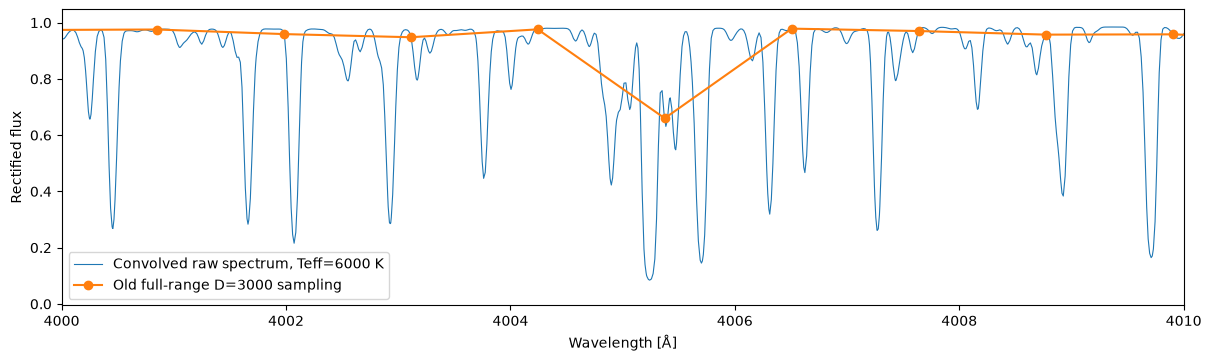

In [5]:
old_wave = np.geomspace(3000, 7000, 3000)
old_wave = old_wave[(old_wave >= WAVE_MIN) & (old_wave <= WAVE_MAX)]
# Add exact endpoints so this local coarse-grid control has common support, without extrapolation.
old_wave = np.unique(np.r_[WAVE_MIN, old_wave, WAVE_MAX])
example = raw_reference_example
fig, ax = plt.subplots(figsize=(12, 3.5), layout='constrained')
ax.plot(example['wave'], example['flux'], lw=.8, label=f'Convolved raw spectrum, Teff={example["teff"]:.0f} K')
ax.plot(old_wave, np.interp(old_wave, example['wave'], example['flux']), 'o-', label='Old full-range D=3000 sampling')
ax.set(xlim=(4000, 4010), xlabel='Wavelength [Å]', ylabel='Rectified flux')
ax.legend(); fig.savefig(run_dir / 'sampling_check.png', dpi=150); plt.show()

## Fit controlled alternatives and evaluate all of them on the same fine grid

The baseline has K=16, three samples/FWHM, NNDSVD-average initialization, and **no weak-absorption cutoff**. Other cases change one choice at a time. Random initializations use two seeds. The old-grid case deliberately reproduces the sampling defect for comparison; it is not a recommended model.

Training and coefficient solves use the shared `SpectralNMF` API, and each fitted artifact is round-trip checked through `NMFCache`. For each case, interpolate its optical-depth basis onto the common four-sample/FWHM reference grid and solve **new non-negative weights with that basis fixed** for every held-out spectrum. Every method is scored against the same unthresholded fine-grid truth. This gives a coarse basis the opportunity to fit on the fine grid, rather than hiding missing lines by evaluating only its coarse training pixels.

Errors from this experiment concern a restricted wavelength interval and a small, balanced sample. Fixed-F coefficient fitting and the later continuum fit are separate from NMF basis training.

The coarse-grid control adds two exact interval endpoints to the old interior samples. This gives every basis common support and avoids extrapolation at the comparison boundaries; it does not restore its missing interior line structure.

In [6]:
cases = [
    dict(name='baseline_3ppf', samples=3, threshold=0.0, init='nndsvda', seed=0),
    dict(name='threshold_0p01', samples=3, threshold=0.01, init='nndsvda', seed=0),
    dict(name='sampling_2ppf', samples=2, threshold=0.0, init='nndsvda', seed=0),
    dict(name='old_D3000_grid', samples=None, threshold=0.0, init='nndsvda', seed=0),
    dict(name='random_seed0', samples=3, threshold=0.0, init='random', seed=0),
    dict(name='random_seed1', samples=3, threshold=0.0, init='random', seed=1),
]

records, per_spectrum, fitted = [], [], {}
validation_truth = reference_flux[validation_mask].astype(np.float64)
validation_tau = reference_tau[validation_mask]
for case in tqdm(cases, desc='NMF alternatives'):
    wave = old_wave if case['samples'] is None else wavelength_grid(case['samples'])
    sampled_flux = np.stack([np.interp(wave, reference_wave, f) for f in reference_flux])
    tau = -np.log(np.clip(sampled_flux, FLUX_FLOOR, 1))
    tau[tau < case['threshold']] = 0
    X = tau[train_mask].astype(np.float32)
    csr = sparse.csr_matrix(X)
    storage = dict(density=float(np.count_nonzero(X) / X.size),
                   dense_MB=X.nbytes / 1e6,
                   csr_MB=(csr.data.nbytes + csr.indices.nbytes + csr.indptr.nbytes) / 1e6)
    del csr  # Record occupancy and size without keeping a second matrix in memory.
    model = SpectralNMF(n_components=K, init=case['init'], solver='cd', max_iter=MAX_ITER,
                        tol=TOL, seed=case['seed'], shuffle=True)
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=N_THREADS):
        warnings.simplefilter('always', ConvergenceWarning)
        model.fit(X, wave, preprocessing=dict(
            R_in=R_IN, R_out=R_OUT, wavelength_unit='Angstrom', wavelength_convention='vacuum',
            reference_frame='stellar_rest', optical_depth_threshold=case['threshold'], flux_floor=FLUX_FLOOR),
            source_ids=selection.loc[train_mask, 'filepath'].tolist(),
            cache=NMFCache(run_dir / 'bases'))
    fit_seconds = model.diagnostics['fit_seconds']
    basis = model.components_.astype(np.float64)
    fine_basis = model.evaluate(reference_wave)
    start = time.perf_counter()
    with threadpool_limits(limits=N_THREADS):
        weights = model.transform(validation_tau, wavelengths=reference_wave)
    coefficient_seconds = time.perf_counter() - start
    predicted_tau = weights @ fine_basis
    predicted_flux = np.exp(-predicted_tau)
    residual = predicted_flux - validation_truth
    flux_rmse = np.sqrt(np.mean(residual**2, axis=1))
    tau_relative = np.linalg.norm(predicted_tau - validation_tau) / np.linalg.norm(validation_tau)
    record = {**case, 'pixels': len(wave), 'n_iter': model.diagnostics['n_iter'],
              'iteration_limit_warning': any(issubclass(w.category, ConvergenceWarning) for w in caught),
              'fit_seconds': fit_seconds, 'coefficient_seconds': coefficient_seconds,
              'relative_tau_frobenius': float(tau_relative),
              'flux_rmse': float(np.sqrt(np.mean(residual**2))),
              'median_spectrum_flux_rmse': float(np.median(flux_rmse)),
              'p95_spectrum_flux_rmse': float(np.quantile(flux_rmse, .95)), **storage}
    for region, low, high in [('line_forest', 4000, 4010), ('broad_line_region', 4075, 4125)]:
        mask = (reference_wave >= low) & (reference_wave <= high)
        record[region + '_flux_rmse'] = float(np.sqrt(np.mean(residual[:, mask]**2)))
    records.append(record)
    rows = selection.loc[validation_mask].copy()
    rows['case'] = case['name']; rows['flux_rmse'] = flux_rmse
    per_spectrum.append(rows)
    fitted[case['name']] = dict(model=model, basis=basis, fine_basis=fine_basis, wave=wave,
                                predicted_flux=predicted_flux, weights=weights)
    record['artifact_path'] = str(model.cache_path.relative_to(run_dir))
    # Verify an artifact can be loaded without the input spectra or original grid assumptions.
    reloaded = SpectralNMF.load(model.cache_path)
    np.testing.assert_array_equal(reloaded.components_, model.components_)
    np.testing.assert_array_equal(reloaded.wavelengths, wave)

metrics = pd.DataFrame(records)
validation_metrics = pd.concat(per_spectrum, ignore_index=True)
metrics.to_csv(run_dir / 'metrics.csv', index=False)
validation_metrics.to_csv(run_dir / 'validation_per_spectrum.csv', index=False)
(run_dir / 'cases.json').write_text(json.dumps(cases, indent=2))
display(metrics[['name', 'pixels', 'density', 'dense_MB', 'csr_MB', 'n_iter',
                 'iteration_limit_warning', 'fit_seconds', 'flux_rmse',
                 'relative_tau_frobenius', 'line_forest_flux_rmse', 'broad_line_region_flux_rmse']])
display(validation_metrics.groupby(['case', 't_bin']).flux_rmse.agg(['count', 'median', 'max']))

NMF alternatives:   0%|          | 0/6 [00:00<?, ?it/s]

,name,pixels,density,dense_MB,csr_MB,n_iter,iteration_limit_warning,fit_seconds,flux_rmse,relative_tau_frobenius,line_forest_flux_rmse,broad_line_region_flux_rmse
0,baseline_3ppf,34530,1.000000,14.916960,29.834356,404,False,6.646809,0.063182,0.129678,0.072042,0.062876
1,threshold_0p01,34530,0.941461,14.916960,28.087916,404,False,6.428113,0.063187,0.129671,0.072057,0.062861
2,sampling_2ppf,23021,1.000000,9.945072,19.890580,408,False,4.285667,0.063413,0.129390,0.072872,0.063319
3,old_D3000_grid,356,1.000000,0.153792,0.308020,500,True,0.140297,0.181794,0.411400,0.183744,0.192650
4,random_seed0,34530,1.000000,14.916960,29.834356,500,True,8.142959,0.060959,0.125733,0.067433,0.061128
5,random_seed1,34530,1.000000,14.916960,29.834356,500,True,7.924622,0.060765,0.127661,0.070167,0.061957


count    median       max
case           t_bin                           
baseline_3ppf  0          9  0.040526  0.126056
               1          9  0.065206  0.110748
               2          9  0.054962  0.087714
               3          9  0.056078  0.078102
old_D3000_grid 0          9  0.122595  0.272056
               1          9  0.196663  0.270083
               2          9  0.178663  0.271050
               3          9  0.157879  0.257798
random_seed0   0          9  0.044611  0.130356
               1          9  0.067207  0.101043
               2          9  0.050087  0.069496
               3          9  0.054662  0.078880
random_seed1   0          9  0.041645  0.131594
               1          9  0.063426  0.113561
               2          9  0.046079  0.067084
               3          9  0.044131  0.077865
sampling_2ppf  0          9  0.039712  0.129603
               1          9  0.066822  0.117552
               2          9  0.054935  0.084535
               3          9  0.054795  0.078661
threshold_0p01 0          9  0.040523  0.126119
               1          9  0.065252  0.110779
               2          9  0.054985  0.087783
               3          9  0.056041  0.078013

### Inspect reconstructions and component shapes

Choose cool, middle-temperature and hot validation spectra. Global scores are not sufficient: examine narrow-line residuals and broad wings. All basis vectors below use a stated, common display normalization. Component indices are not physical labels, and the normalized display does not alter stored fitting vectors or fitted coefficients.

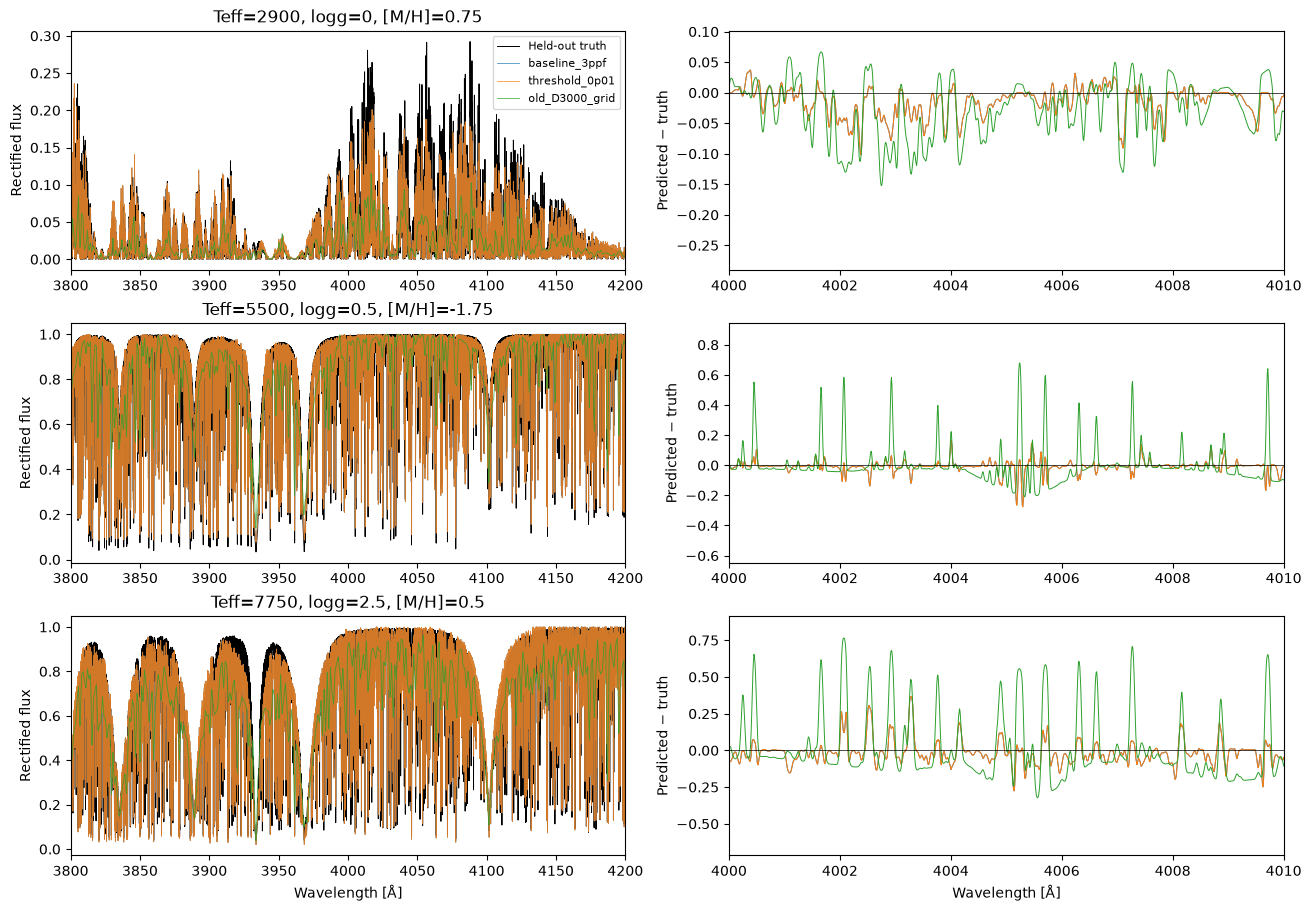

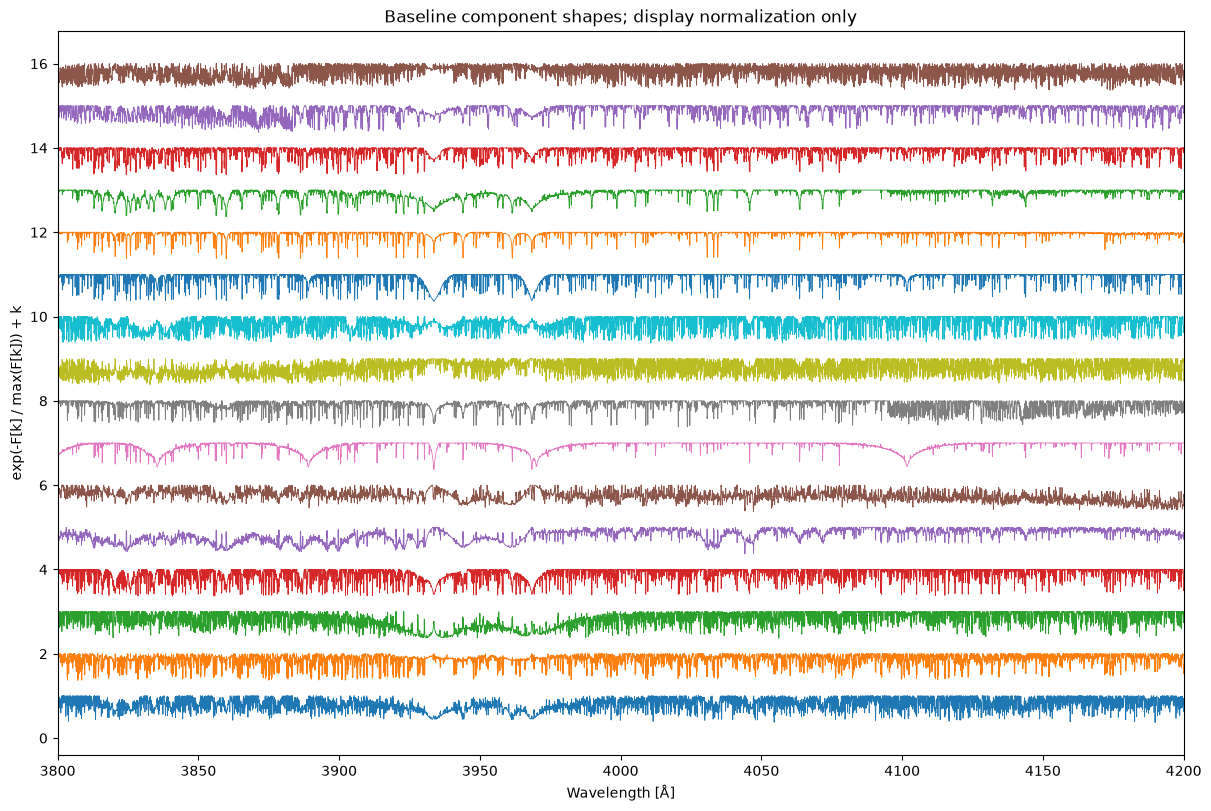

In [7]:
validation_rows = selection.loc[validation_mask].reset_index(drop=True)
ordered = np.argsort(validation_rows.teff.to_numpy())
example_indices = sorted(set([int(ordered[0]), int(ordered[len(ordered)//2]), int(ordered[-1])]))
fig, axes = plt.subplots(len(example_indices), 2, figsize=(13, 3 * len(example_indices)), squeeze=False, layout='constrained')
for row_axes, index in zip(axes, example_indices):
    row = validation_rows.iloc[index]
    row_axes[0].plot(reference_wave, validation_truth[index], color='black', lw=.7, label='Held-out truth')
    for name in ['baseline_3ppf', 'threshold_0p01', 'old_D3000_grid']:
        predicted = fitted[name]['predicted_flux'][index]
        row_axes[0].plot(reference_wave, predicted, lw=.6, alpha=.8, label=name)
        row_axes[1].plot(reference_wave, predicted - validation_truth[index], lw=.7, label=name)
    row_axes[0].set(title=f'Teff={row.teff:.0f}, logg={row.logg:g}, [M/H]={row.metal:g}', ylabel='Rectified flux', xlim=(WAVE_MIN,WAVE_MAX))
    row_axes[1].set(xlim=(4000,4010), ylabel='Predicted − truth')
    row_axes[1].axhline(0, color='black', lw=.5)
axes[0,0].legend(fontsize=8); axes[-1,0].set_xlabel('Wavelength [Å]'); axes[-1,1].set_xlabel('Wavelength [Å]')
fig.savefig(run_dir / 'heldout_reconstructions.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(12, 8), layout='constrained')
for k, f in enumerate(fitted['baseline_3ppf']['fine_basis']):
    scale = max(np.max(f), np.finfo(float).eps)
    ax.plot(reference_wave, np.exp(-f / scale) + k, lw=.6)
ax.set(xlim=(WAVE_MIN,WAVE_MAX), xlabel='Wavelength [Å]', ylabel='exp(-F[k] / max(F[k])) + k',
       title='Baseline component shapes; display normalization only')
fig.savefig(run_dir / 'baseline_basis_shapes.png', dpi=150); plt.show()

## Synthetic continuum recovery on held-out stellar spectra

Multiply held-out theoretical spectra by a known, smooth continuum and add Gaussian noise with S/N=100 **at the continuum level**. Fit stellar weights and continuum coefficients simultaneously, with no tellurics and known zero radial velocity. The continuum is generated within the Fourier family to isolate absorption-basis errors; this does not test whether Fourier functions capture a real instrument's response.

The true absorption is the held-out BOSZ spectrum, not a spectrum synthesized from the fitted basis. Thus finite-K mismatch remains present. Use the paper's second-order approximation to log-flux variance, and report how many noisy non-positive pixels are excluded. This is a focused synthetic test, not evidence of accuracy on real HARPS observations.

This modest diagnostic uses the dense exact linear solver with a 500-iteration outer limit. The production normalizer retains sparse iterative least squares by default. Always inspect `solver_success`; unsuccessful solves do not establish continuum accuracy.

For continuum scoring, reconstruct `exp(H @ gamma)` over the full interval, including excluded noisy pixels; observation-level result arrays intentionally contain NaN at excluded pixels. The coefficient fit itself still uses only retained pixels, and the excluded count is reported.

,validation_index,case,teff,continuum_fractional_rmse,continuum_max_absolute_fractional_error,excluded_pixels,solver_success,solver_status,solver_message
0,2,baseline_3ppf,2900.0,0.281316,0.465357,7045,True,1,The first-order optimality measure is less tha...
1,2,threshold_0p01,2900.0,0.281382,0.465180,7045,True,1,The first-order optimality measure is less tha...
2,2,old_D3000_grid,2900.0,0.794340,0.941201,7045,True,2,The relative change of the cost function is le...
3,18,baseline_3ppf,5500.0,0.036031,0.054734,0,True,2,The relative change of the cost function is le...
4,18,threshold_0p01,5500.0,0.036113,0.055349,0,True,2,The relative change of the cost function is le...
5,18,old_D3000_grid,5500.0,0.013997,0.036072,0,True,2,The relative change of the cost function is le...
6,32,baseline_3ppf,7750.0,0.065860,0.123411,0,True,2,The relative change of the cost function is le...
7,32,threshold_0p01,7750.0,0.064684,0.122662,0,True,2,The relative change of the cost function is le...
8,32,old_D3000_grid,7750.0,0.090107,0.122536,0,True,2,The relative change of the cost function is le...


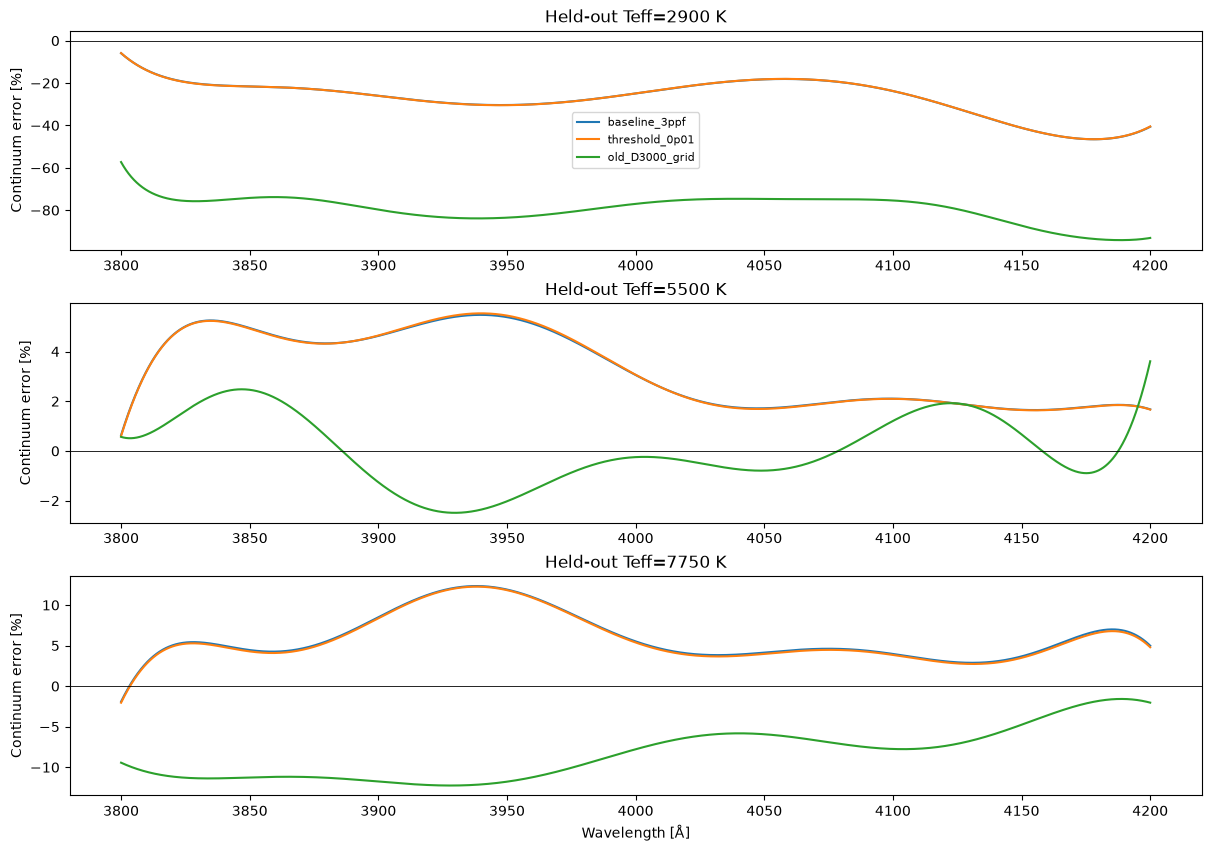

Artifacts: /home/mward19/Documents/stellar-continuum-normalization/reports/bosz_subset_validation/20261113T173554_838001Z


In [2]:
response_basis = ContinuumResponseBasis(9)
H = response_basis.design_matrix(reference_wave).toarray()
# Small coefficients produce a positive, smoothly varying response after exponentiation.
true_gamma = np.array([.1, .025, -.035, .015, .02, 0, 0, 0, 0])
true_continuum = np.exp(H @ true_gamma)
snr = 100.0
noise_sigma = true_continuum / snr
rng_noise = np.random.default_rng(SEED + 1)
continuum_indices = example_indices
continuum_records, continuum_predictions = [], {}
for index in continuum_indices:
    true_flux = validation_truth[index] * true_continuum
    noisy_flux = true_flux + rng_noise.normal(size=len(true_flux)) * noise_sigma
    good = np.isfinite(noisy_flux) & (noisy_flux > 0)
    for name in ['baseline_3ppf', 'threshold_0p01', 'old_D3000_grid']:
        normalizer = ContinuumNormalizer(fitted[name]['model'], response_basis=response_basis, variance_order=2)
        with threadpool_limits(limits=N_THREADS):
            result = normalizer.fit(reference_wave, noisy_flux, noise_sigma, tol=1e-8, lsq_solver='exact', max_iter=500)
        # Score the known smooth response across the full interval, including excluded noisy pixels.
        # Observation-level outputs intentionally contain NaN at excluded pixels.
        recovered = np.exp(H @ result.gamma.ravel())
        np.testing.assert_allclose(recovered[result.mask], result.continuum[result.mask])
        fractional_error = recovered / true_continuum - 1
        continuum_predictions[(index, name)] = recovered
        continuum_records.append(dict(validation_index=index, case=name,
            teff=validation_rows.iloc[index].teff,
            continuum_fractional_rmse=float(np.sqrt(np.mean(fractional_error**2))),
            continuum_max_absolute_fractional_error=float(np.max(np.abs(fractional_error))),
            excluded_pixels=int((~good).sum()), solver_success=bool(result.success),
            solver_status=int(result.status), solver_message=result.message))
continuum_metrics = pd.DataFrame(continuum_records)
continuum_metrics.to_csv(run_dir / 'continuum_metrics.csv', index=False)
display(continuum_metrics)
fig, axes = plt.subplots(len(continuum_indices), 1, figsize=(12, 2.8 * len(continuum_indices)), squeeze=False, layout='constrained')
for ax, index in zip(axes[:,0], continuum_indices):
    for name in ['baseline_3ppf', 'threshold_0p01', 'old_D3000_grid']:
        ax.plot(reference_wave, 100 * (continuum_predictions[(index,name)] / true_continuum - 1), label=name)
    ax.axhline(0, color='black', lw=.6)
    ax.set(ylabel='Continuum error [%]', title=f'Held-out Teff={validation_rows.iloc[index].teff:.0f} K')
axes[0,0].legend(fontsize=8); axes[-1,0].set_xlabel('Wavelength [Å]')
fig.savefig(run_dir / 'continuum_recovery.png', dpi=150); plt.show()
print('Artifacts:', run_dir.resolve())

## Interpret the results before increasing the workload

- Inspect coverage first. This is a small balanced diagnostic subset, not proof of performance over the full BOSZ grid. If one region performs poorly, increase its training-group coverage before interpreting component physics.
- Check iteration-limit warnings and solver success. Re-run promising cases with a larger iteration budget if needed; a low stopping statistic does not imply small held-out error.
- Compare every case on the common fine-grid flux residuals. Look separately at weak blends, the line forest, and broad wings. Do not select a model by component-zero appearance.
- Compare the two random starts with the baseline; extend to more seeds if they differ substantially. Consider a K sweep only after checking preprocessing and convergence.
- Density and storage columns show whether CSR is worthwhile. The timed fits here are all dense to keep the numerical comparison consistent; a dense-versus-sparse speed benchmark must use the same X and thread count in a separate experiment.
- Four samples/FWHM defines the reference here. Before full production training, repeat with a finer reference and check that conclusions are stable, and verify the native BOSZ resolution prescription.
- Synthetic continuum recovery uses one smooth response family, three held-out stellar examples, a single noise realization, known RV and no tellurics. Broader validation needs additional continuum shapes, noise seeds/S/N values, real observations, and a separate telluric test.

This notebook now exercises the public refactored APIs. The held-out BOSZ flux, shared fine-grid metrics, and known synthetic continuum remain independent reference targets. Use the same selection manifest to compare later algorithm or preprocessing changes.